# Exercice 3 : Un domaine révèle son organisation

> **En une phrase :** à partir du seul mot « uqac.ca », on retrouve des **centaines de noms de serveurs**, les **fournisseurs** de l'université et des **contacts**, sans envoyer un seul paquet à l'UQAC.

**Le scénario.** C'est l'accroche du cours, en vrai. On joue l'attaquant en phase **passive** : on ne lit que des sources publiques.

**Les sources.**
- **crt.sh** : les journaux *Certificate Transparency*. Chaque certificat TLS émis est publié, avec les noms de serveurs qu'il protège.
- **DNS public** (via dns.google) : courriel, fournisseurs, sécurité du courriel.
- **RDAP** (le successeur du WHOIS) : qui a enregistré le domaine.

**Le plan.**
1. Lister les sous-domaines grâce aux certificats.
2. Repérer les noms intéressants pour un attaquant.
3. Lire le DNS : courriel et fournisseurs.
4. Lire le WHOIS.
5. Contre-mesures.

## Étape 0 : exécutez cette cellule en premier
Le notebook est **autonome** : il fonctionne tel quel sur Colab (ouvert depuis Drive) ou en local. Elle doit afficher **Prêt**.

In [1]:
import requests

def dns(nom, type_enr="A"):
    """Pose une question DNS publique (via dns.google) et renvoie la liste des réponses."""
    codes = {"A": 1, "NS": 2, "CNAME": 5, "MX": 15, "TXT": 16}
    rep = requests.get("https://dns.google/resolve", params={"name": nom, "type": type_enr}, timeout=10).json()
    return [r["data"].strip('"') for r in rep.get("Answer", []) if r["type"] == codes[type_enr]]

import time

def sous_domaines(domaine):
    """Liste les noms trouvés dans les journaux Certificate Transparency (crt.sh)."""
    for essai in range(3):                       # crt.sh est parfois lent : on réessaie
        try:
            certs = requests.get("https://crt.sh/", params={"q": "%." + domaine, "output": "json"}, timeout=90).json()
            break
        except Exception:
            print("crt.sh ne répond pas, nouvel essai…"); time.sleep(5)
    else:
        raise RuntimeError("crt.sh indisponible : réessayez dans une minute.")
    noms = set()
    for c in certs:
        for n in c["name_value"].split("\n"):
            n = n.strip().lower().removeprefix("*.")
            if n.endswith(domaine):
                noms.add(n)
    return certs, sorted(noms)

import collections
import pandas as pd
print('Prêt')

Prêt


## Étape 1 : Lister les sous-domaines grâce aux certificats
**Ce qu'on fait :** on demande à crt.sh tous les certificats émis pour `*.uqac.ca`. *(Peut prendre 20 à 60 secondes.)*

1367 certificats, 164 noms de machines distincts


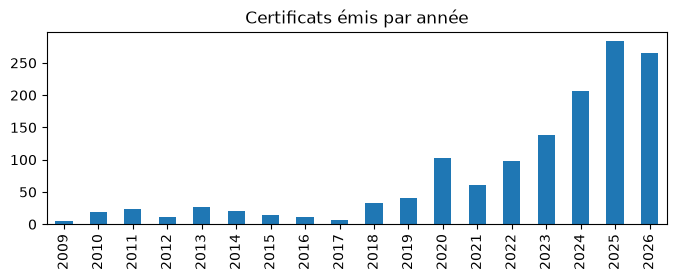

In [2]:
domaine = "uqac.ca"      # <-- MODIFIABLE (règle du cours : l'UQAC ou un domaine qui vous appartient)

certs, noms = sous_domaines(domaine)
print(f"{len(certs)} certificats, {len(noms)} noms de machines distincts")

annees = collections.Counter(c["not_before"][:4] for c in certs)
pd.Series(annees).sort_index().plot(kind="bar", title="Certificats émis par année", figsize=(8, 2.5));

**👀 Ce qu'on doit voir :** ≈ **1 360 certificats** et ≈ **160 noms** distincts, depuis **2009**. La forte hausse après 2019 vient des certificats gratuits renouvelés automatiquement tous les 90 jours.

## Étape 2 : Repérer les noms intéressants pour un attaquant
**Ce qu'on fait :** on cherche des mots qui trahissent des serveurs **moins protégés** (développement, test) ou **stratégiques** (VPN, courriel).

In [3]:
mots_cles = ["dev", "test", "vpn", "mail", "owa", "api", "admin", "intranet", "backup"]   # <-- MODIFIABLE

for mot in mots_cles:
    trouves = [n for n in noms if mot in n.split(".")[0]]
    if trouves:
        print(f"{mot:6} ({len(trouves):2}) : {', '.join(trouves[:4])}{' …' if len(trouves) > 4 else ''}")

dev    (15) : cibc-dev.uqac.ca, constellation-dev.uqac.ca, devops.uqac.ca, sd-passa-dev.uqac.ca …
test   ( 3) : safirhtest.uqac.ca, test.uqac.ca, testentrust.uqac.ca
vpn    ( 1) : vpn-uqac1.uqac.ca
mail   ( 3) : mailetud.uqac.ca, mailpers.uqac.ca, sc-mailextb.uqac.ca
owa    ( 1) : owa.uqac.ca
api    ( 1) : apis.uqac.ca


**👀 Ce qu'on doit voir :** ≈ **15 noms en « -dev »**, quelques « test », un VPN, des serveurs de courriel. Le nom seul dit à quoi sert la machine.

In [4]:
# Combien de ces noms existent encore, vus depuis Internet ?
publics = {n: dns(n, "A") for n in noms}
publics = {n: ip for n, ip in publics.items() if ip}
print(f"{len(publics)} noms sur {len(noms)} répondent encore publiquement")

43 noms sur 164 répondent encore publiquement


**👀 Ce qu'on doit voir :** ≈ **42 sur 163**. Les autres sont des serveurs **internes** ou disparus… mais leurs noms sont publiés **pour toujours** dans les journaux de certificats.

## Étape 3 : Lire le DNS : courriel et fournisseurs
**Ce qu'on fait :** on lit trois types d'enregistrements :
- **MX** : qui reçoit le courriel ?
- **TXT** : les preuves de propriété laissées pour des services en ligne (« google-site-verification=… »), et la politique **SPF**.
- **DMARC** : que faire d'un courriel qui prétend venir de uqac.ca sans le prouver ?

In [5]:
print("Courriel (MX) :", dns(domaine, "MX"))
print()
txt = dns(domaine, "TXT")
fournisseurs = [t.split("=")[0] for t in txt if "verification" in t or t.startswith("MS=")]
print("Fournisseurs révélés :", fournisseurs)
print()
print("SPF   :", [t[:90] + "…" for t in txt if t.startswith("v=spf1")])
print("DMARC :", dns("_dmarc." + domaine, "TXT"))

Courriel (MX) : ['0 uqac-ca.mail.protection.outlook.com.']



Fournisseurs révélés : ['sophos-domain-verification', 'MS', 'abuseipdb-verification', 'facebook-domain-verification', 'atlassian-domain-verification', 'google-site-verification', 'logmein-verification-code', 'apple-domain-verification']

SPF   : ['v=spf1 ip4:132.212.11.149 ip4:132.212.2.236 ip4:132.212.2.240/29 ip4:132.212.11.48 ip4:132…']


DMARC : ['v=DMARC1; p=reject;sp=quarantine;rua=mailto:dmarc_agg@vali.email;fo=1;']


**👀 Ce qu'on doit voir :**
- MX : **outlook.com** → le courriel est chez Microsoft 365.
- **8 fournisseurs** : LogMeIn, Google, Sophos, Microsoft (`MS=`), Atlassian, Apple, AbuseIPDB, Facebook.
- DMARC : **p=reject** → un courriel usurpant « @uqac.ca » est rejeté. Bon point pour l'UQAC.

**❓ Question pour la classe :** l'attaquant sait maintenant que l'UQAC utilise Sophos et Atlassian. Comment s'en sert-il ?

*Réponse : pour un **prétexte crédible**. Un faux courriel « Alerte Sophos : votre poste est infecté, cliquez ici » ou « Atlassian : partage d'une page Confluence » a bien plus de chances de fonctionner, puisque les employés connaissent ces outils.*

**❓ Deuxième question :** pourquoi passe-t-on par `dns.google` au lieu du DNS de notre propre machine ?

*Réponse : sur le réseau de l'UQAC, la machine interroge le DNS **interne** de l'université, qui donne une vue différente (des noms internes, pas de MX…). L'attaquant, lui, est dehors : on veut **sa** vue.*

## Étape 4 : Lire le WHOIS (RDAP)
**Ce qu'on fait :** on interroge le registre canadien (CIRA) : qui a enregistré le domaine, et qui sont les contacts ? *(Les noms sont masqués ici : on veut savoir s'ils sont exposés, pas les diffuser.)*

In [6]:
rdap = requests.get(f"https://rdap.ca.fury.ca/rdap/domain/{domaine}", timeout=15).json()

def masquer(nom):
    return " ".join(m[0] + "*" * (len(m) - 1) for m in nom.split()) if nom else "(vide)"

print("Créé le :", next(e["eventDate"][:10] for e in rdap["events"] if e["eventAction"] == "registration"))
for entite in rdap.get("entities", []):
    vcard = {champ[0]: champ[3] for champ in entite.get("vcardArray", [None, []])[1]}
    print(f"{entite['roles'][0]:15} nom : {masquer(vcard.get('fn', '')):25} organisation : {vcard.get('org', '')}")

Créé le : 2000-11-09
registrar       nom : A***** I*********** I***  organisation : 
registrant      nom : U********* d* Q***** a C********* organisation : Universite du Quebec a Chicoutimi
administrative  nom : G******* G********        organisation : Université du Québec à Chicoutimi
technical       nom : J************* G*****     organisation : Université du Québec à Chicoutimi
billing         nom : (vide)                    organisation : 


**👀 Ce qu'on doit voir :** domaine créé en **2000**, le **registraire** (le sous-traitant), et **deux contacts nommés** (administratif et technique). Deux vraies personnes, avec leur rôle : des cibles idéales pour l'hameçonnage.

## Étape 5 : Contre-mesures
**Ce qu'on fait :** pour chaque découverte, la mesure qui la réduit.

| Découverte | Contre-mesure |
|---|---|
| Noms internes et « -dev » dans les certificats | Certificat **générique** (`*.interne.uqac.ca`) ou autorité de certification **interne** pour ce qui n'est pas public |
| Fournisseurs dans les TXT | Retirer les preuves de propriété une fois la vérification faite |
| Contacts nommés dans le WHOIS | Adresse de **rôle** (`domaine@…`) et nom générique (« Service des TI ») |
| Usurpation du courriel | SPF + **DMARC p=reject** (déjà fait à l'UQAC) |

## Ce qu'il faut retenir
- Un nom de domaine suffit pour cartographier une organisation : **serveurs**, **fournisseurs**, **personnes**.
- Les journaux de certificats sont **publics et permanents** : un nom de serveur publié une fois l'est pour toujours.
- Tout cela est **passif** : l'UQAC n'a rien vu passer.

**Exercice suivant :** on a des adresses IP. Quels **services** tournent dessus ? Toujours sans rien leur envoyer.